<a href="https://colab.research.google.com/github/Nihat0311/Computer-Vision/blob/main/Transfer_learning_bezileri.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from functools import partial

class ResidualUnit(nn.Module):
    def __init__(self,in_channel,out_channel,stride=1):
      super().__init__()

      DefaultConv2d=partial(
          nn.Conv2d,
          kernel_size=3,
          padding=1,
          stride=1
      )
      self.main_layers=nn.Sequential(
          DefaultConv2d(in_channel,out_channel,stride=stride),
          nn.BatchNorm2d(out_channel),
          nn.ReLU(),
          DefaultConv2d(out_channel,out_channel),
          nn.BatchNorm2d(out_channel)
      )
      if stride>1:
        self.skip_connection=nn.Sequential(
            DefaultConv2d(in_channel,out_channel,stride=stride,padding=0,kernel_size=1),
            nn.BatchNorm2d(out_channel)
        )
      else:
        self.skip_connection=nn.Sequential()
    def forward(self,input):
      return F.relu(self.main_layers(input)+self.skip_connection(input))


In [ ]:
class ResNet34(nn.Module):
  def __init__(self):
    super().__init__()
    layers=[
        nn.Conv2d(in_channels=3,out_channels=64,kernel_size=7,stride=2,padding=3,bias=False),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=3,stride=2,padding=1)
    ]
    prev_filters=64
    for filters in [64]*3+[128]*4+[256]*6+[512]*3:
      stride=1 if filters==prev_filters else 2
      layers.append(ResidualUnit(prev_filters,filters,stride=stride))
      prev_filters=filters
    layers+=[
        nn.AdaptiveAvgPool2d(output_size=1),
        nn.Flatten(),
        nn.LazyLinear(10)
    ]
    self.resnet=nn.Sequential(*layers)

  def forward(self,input):
    return self.resnet(input)

In [ ]:
import torchvision
import torch

device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
weights=torchvision.models.ConvNeXt_Base_Weights.IMAGENET1K_V1
model=torchvision.models.convnext_base(weights=weights).to(device)

Downloading: "https://download.pytorch.org/models/convnext_base-6075fbad.pth" to /root/.cache/torch/hub/checkpoints/convnext_base-6075fbad.pth


100%|██████████| 338M/338M [00:01<00:00, 201MB/s]


In [ ]:
from sklearn.datasets import load_sample_images
import numpy as np
sample_images=np.stack(load_sample_images()['images'])
sample_images=torch.tensor(sample_images,dtype=torch.float32)/255

In [ ]:
sample_images_permuted=sample_images.permute(0,3,1,2)

In [ ]:
transforms=weights.transforms()
preprocessed_images=transforms(sample_images_permuted)

In [ ]:
model.eval()
with torch.no_grad():
  y_logits=model(preprocessed_images.to(device))

In [ ]:
y_pred=torch.argmax(y_logits,dim=1)
y_pred

tensor([698, 985], device='cuda:0')

In [ ]:
class_names=weights.meta['categories']
[class_names[class_id] for class_id in y_pred]

['palace', 'daisy']

In [ ]:
y_top_3_logits,y_top3_class_ids=y_logits.topk(k=3,dim=1)
[[class_names[class_id] for class_id in top3] for top3 in y_top3_class_ids]

[['palace', 'monastery', 'lakeside'], ['daisy', 'pot', 'ant']]

In [ ]:
y_top_3_logits.softmax(dim=1)

tensor([[0.8618, 0.1185, 0.0197],
        [0.8106, 0.0964, 0.0930]], device='cuda:0')

In [ ]:
DefaultFlowers102 =partial(
    torchvision.datasets.Flowers102,
    root='datasets',
    download=True,
    transform=weights.transforms()
)
train_set=DefaultFlowers102(split='train')
test_set=DefaultFlowers102(split='test')
val_set=DefaultFlowers102(split='val')

100%|██████████| 345M/345M [00:16<00:00, 20.9MB/s]
100%|██████████| 502/502 [00:00<00:00, 1.81MB/s]
100%|██████████| 15.0k/15.0k [00:00<00:00, 48.4MB/s]


In [ ]:
from torch.utils.data import DataLoader

train_loader=DataLoader(train_set,batch_size=32,shuffle=True)
test_loader=DataLoader(test_set,batch_size=32,shuffle=False)
valid_loader=DataLoader(val_set,batch_size=32,shuffle=False)

In [ ]:
[name for name,child in model.named_children()]

['features', 'avgpool', 'classifier']

In [ ]:
n_classes=102
model.classifier[2]=nn.Linear(1024,n_classes).to(device)

In [ ]:
for param in model.parameters():
  param.requires_grad=False
for param in model.classifier.parameters():
  param.requires_grad=True

In [ ]:
import torchvision.transforms.v2 as T

transforms = T.Compose([
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=30),
    T.RandomResizedCrop(size=(224, 224), scale=(0.8, 1.0)),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    T.ToImage(),
    T.ToDtype(torch.float32, scale=True),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

In [ ]:
import torch.optim as  optim

In [ ]:
criterion=nn.CrossEntropyLoss()
optimizer=optim.AdamW(model.classifier.parameters(),lr=1e-3,weight_decay=1e-4)


In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    running_correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)


        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        running_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        running_correct += (preds == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = running_correct / total
    return epoch_loss, epoch_acc


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    running_correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        running_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        running_correct += (preds == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = running_correct / total
    return epoch_loss, epoch_acc


In [ ]:
epoch_stage1=5

for epoch in range(epoch_stage1):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    valid_loss, valid_acc = evaluate(model, valid_loader, criterion, device)
    print(
        f"Epoch: {epoch+1}/{epoch_stage1}, "
        f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}, "
        f"Valid Loss: {valid_loss:.4f}, Valid Acc: {valid_acc:.4f}"
    )

Epoch: 1/5, Train Loss: 4.3069, Train Acc: 0.1569, Valid Loss: 3.4928, Valid Acc: 0.5098
Epoch: 2/5, Train Loss: 3.0303, Train Acc: 0.6471, Valid Loss: 2.5174, Valid Acc: 0.7431
Epoch: 3/5, Train Loss: 2.0635, Train Acc: 0.8412, Valid Loss: 1.8051, Valid Acc: 0.8147
Epoch: 4/5, Train Loss: 1.3798, Train Acc: 0.9000, Valid Loss: 1.3512, Valid Acc: 0.8480
Epoch: 5/5, Train Loss: 0.9617, Train Acc: 0.9412, Valid Loss: 1.0579, Valid Acc: 0.8637


In [ ]:
for param in model.parameters():
  param.requires_grad=True
optimizer=optim.AdamW(model.parameters(),lr=1e-4,weight_decay=1e-4)
epoch_stage2=5

for epoch in range(epoch_stage2):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    valid_loss, valid_acc = evaluate(model, valid_loader, criterion, device)
    print(
        f"Epoch: {epoch+1}/{epoch_stage2}, "
        f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}, "
        f"Valid Loss: {valid_loss:.4f}, Valid Acc: {valid_acc:.4f}"
    )

Epoch: 1/10, Train Loss: 0.2990, Train Acc: 0.9775, Valid Loss: 0.3451, Valid Acc: 0.9412
Epoch: 2/10, Train Loss: 0.0618, Train Acc: 0.9980, Valid Loss: 0.2622, Valid Acc: 0.9569
Epoch: 3/10, Train Loss: 0.0266, Train Acc: 1.0000, Valid Loss: 0.2386, Valid Acc: 0.9520
Epoch: 4/10, Train Loss: 0.0169, Train Acc: 1.0000, Valid Loss: 0.2140, Valid Acc: 0.9667
Epoch: 5/10, Train Loss: 0.0125, Train Acc: 1.0000, Valid Loss: 0.2038, Valid Acc: 0.9637
Epoch: 6/10, Train Loss: 0.0097, Train Acc: 1.0000, Valid Loss: 0.1991, Valid Acc: 0.9647
Epoch: 7/10, Train Loss: 0.0080, Train Acc: 1.0000, Valid Loss: 0.1908, Valid Acc: 0.9667
Epoch: 8/10, Train Loss: 0.0067, Train Acc: 1.0000, Valid Loss: 0.1835, Valid Acc: 0.9637
Epoch: 9/10, Train Loss: 0.0060, Train Acc: 1.0000, Valid Loss: 0.1808, Valid Acc: 0.9676
Epoch: 10/10, Train Loss: 0.0050, Train Acc: 1.0000, Valid Loss: 0.1772, Valid Acc: 0.9686


In [ ]:
test_loss, test_acc = evaluate(model, test_loader, criterion, device)
print(f"Test Loss: {test_loss:.4f}, Test Acc: {test_acc:.4f}")

Test Loss: 0.2276, Test Acc: 0.9520


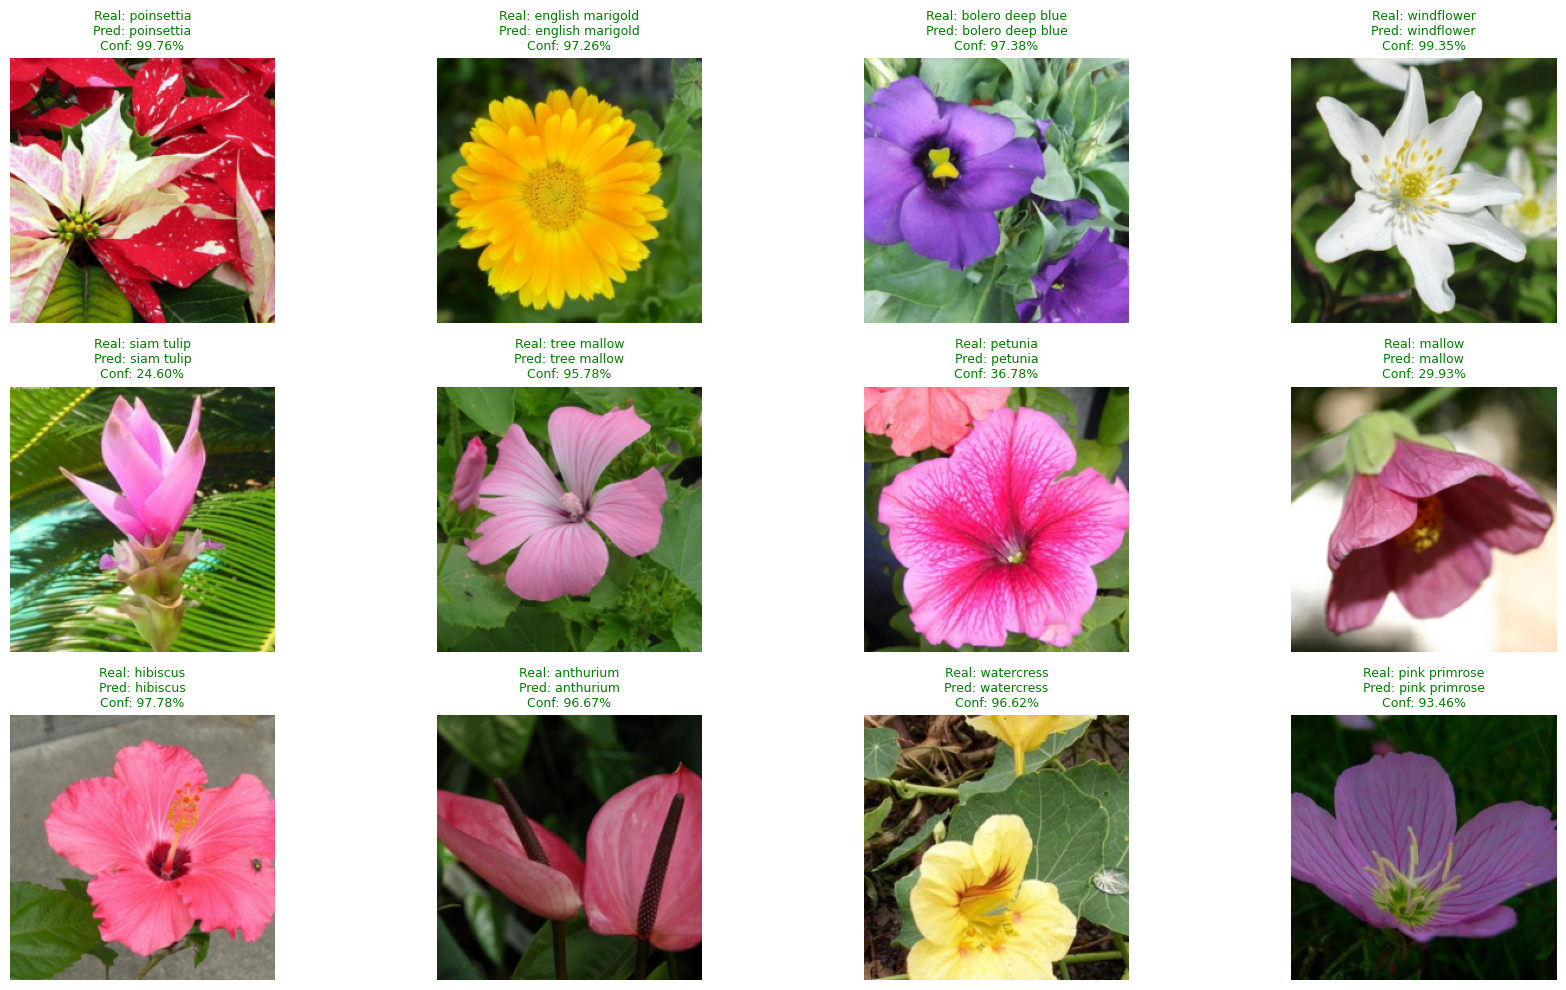

In [ ]:
import json
import urllib.request
import random
import matplotlib.pyplot as plt


url = "https://raw.githubusercontent.com/udacity/aipnd-project/master/cat_to_name.json"
urllib.request.urlretrieve(url, "cat_to_name.json")

with open("cat_to_name.json", "r") as f:
    cat_to_name = json.load(f)

class_names = [cat_to_name[str(i)] for i in range(1, 103)]


mean = torch.tensor([0.485, 0.456, 0.406])
std = torch.tensor([0.229, 0.224, 0.225])

indices = random.sample(range(len(test_set)), 12)

model.eval()
plt.figure(figsize=(18, 10))

for i, idx in enumerate(indices):
    image, true_label = test_set[idx]

    input_image = image.unsqueeze(0).to(device)

    with torch.no_grad():
        logits = model(input_image)
        probs = torch.softmax(logits, dim=1)
        pred_prob, pred_label = probs.max(dim=1)

    pred_label = pred_label.item()
    pred_prob = pred_prob.item()

    img = image.cpu() * std[:, None, None] + mean[:, None, None]
    img = img.clamp(0, 1).permute(1, 2, 0)

    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.axis("off")

    color = "green" if pred_label == true_label else "red"

    plt.title(
        f"Real: {class_names[true_label]}\n"
        f"Pred: {class_names[pred_label]}\n"
        f"Conf: {pred_prob:.2%}",
        color=color,
        fontsize=9
    )

plt.tight_layout()
plt.show()